# ✅ OUTLIER HANDLING USING IQR METHOD (TRIMMING + CAPPING)
##### Dataset: placement.csv
##### Column Focus: placement_exam_marks
#####
##### IQR Method:
#####   Q1 = 25th percentile
#####   Q3 = 75th percentile
#####   IQR = Q3 - Q1
#####
##### Outlier Limits:
#####   Lower Limit = Q1 - 1.5 * IQR
#####   Upper Limit = Q3 + 1.5 * IQR
#####
##### Handling Methods:
##### ✅ Trimming = remove outlier rows
##### ✅ Capping  = replace outlier values with upper/lower limit

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Step 1) Load Dataset
# -------------------------------
df = pd.read_csv("placement2.csv")

print("✅ Dataset shape:", df.shape)
print("\n✅ First 5 rows:\n", df.head())

✅ Dataset shape: (1000, 3)

✅ First 5 rows:
    cgpa  placement_exam_marks  placed
0  7.19                  26.0       1
1  7.46                  38.0       1
2  7.54                  40.0       1
3  6.42                   8.0       1
4  7.23                  17.0       0


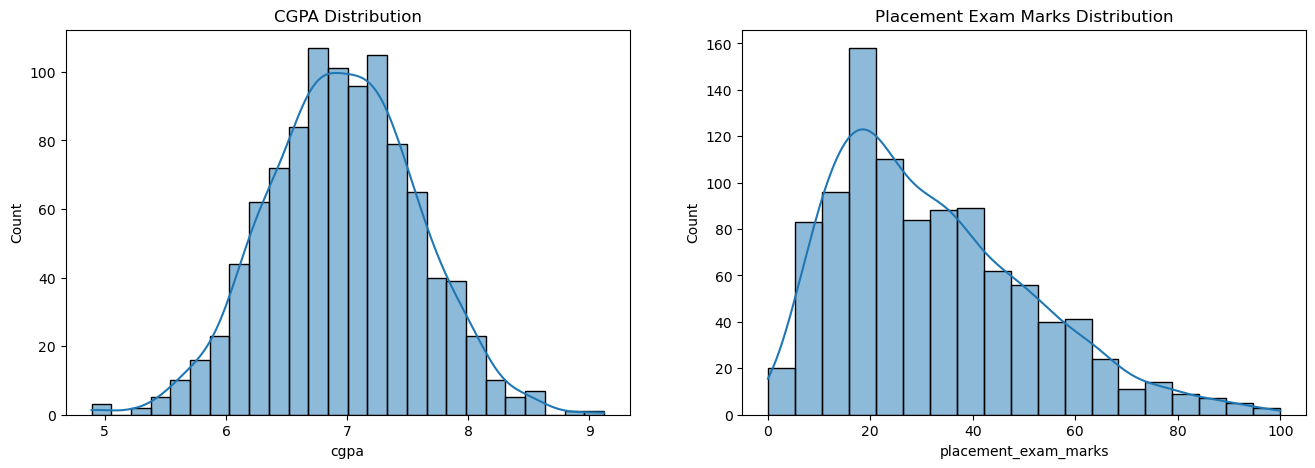

In [3]:
# -------------------------------
# Step 2) Distribution Plots
# (Using histplot because distplot is deprecated)
# -------------------------------
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["cgpa"], kde=True)
plt.title("CGPA Distribution")

plt.subplot(1, 2, 2)
sns.histplot(df["placement_exam_marks"], kde=True)
plt.title("Placement Exam Marks Distribution")

plt.show()



✅ placement_exam_marks Summary:
 count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64


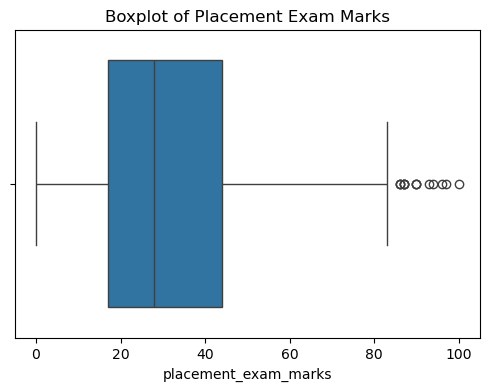

In [4]:
# -------------------------------
# Step 3) Describe + Boxplot
# -------------------------------
print("\n✅ placement_exam_marks Summary:\n", df["placement_exam_marks"].describe())

plt.figure(figsize=(6, 4))
sns.boxplot(x=df["placement_exam_marks"])
plt.title("Boxplot of Placement Exam Marks")
plt.show()

In [5]:
# -------------------------------
# Step 4) Find IQR + Limits
# -------------------------------
percentile25 = df["placement_exam_marks"].quantile(0.25)
percentile75 = df["placement_exam_marks"].quantile(0.75)

iqr = percentile75 - percentile25

upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr

print("\n✅ IQR Calculation:")
print("Q1 (25%) =", percentile25)
print("Q3 (75%) =", percentile75)
print("IQR      =", iqr)

print("\n✅ Outlier Limits:")
print("Upper limit =", upper_limit)
print("Lower limit =", lower_limit)


✅ IQR Calculation:
Q1 (25%) = 17.0
Q3 (75%) = 44.0
IQR      = 27.0

✅ Outlier Limits:
Upper limit = 84.5
Lower limit = -23.5


In [6]:
# -------------------------------
# Step 5) Find Outliers
# -------------------------------
upper_outliers = df[df["placement_exam_marks"] > upper_limit]
lower_outliers = df[df["placement_exam_marks"] < lower_limit]

print("\n✅ Upper Outliers Count:", upper_outliers.shape[0])
print("✅ Lower Outliers Count:", lower_outliers.shape[0])

print("\n✅ Upper Outliers:\n", upper_outliers)

print("\n✅ Lower Outliers:\n", lower_outliers)


✅ Upper Outliers Count: 15
✅ Lower Outliers Count: 0

✅ Upper Outliers:
      cgpa  placement_exam_marks  placed
9    7.75                  94.0       1
40   6.60                  86.0       1
61   7.51                  86.0       0
134  6.33                  93.0       0
162  7.80                  90.0       0
283  7.09                  87.0       0
290  8.38                  87.0       0
311  6.97                  87.0       1
324  6.64                  90.0       0
630  6.56                  96.0       1
685  6.05                  87.0       1
730  6.14                  90.0       1
771  7.31                  86.0       1
846  6.99                  97.0       0
917  5.95                 100.0       0

✅ Lower Outliers:
 Empty DataFrame
Columns: [cgpa, placement_exam_marks, placed]
Index: []


# ✅ METHOD 1: TRIMMING (Remove Outliers)



✅ Shape after Trimming: (985, 3)


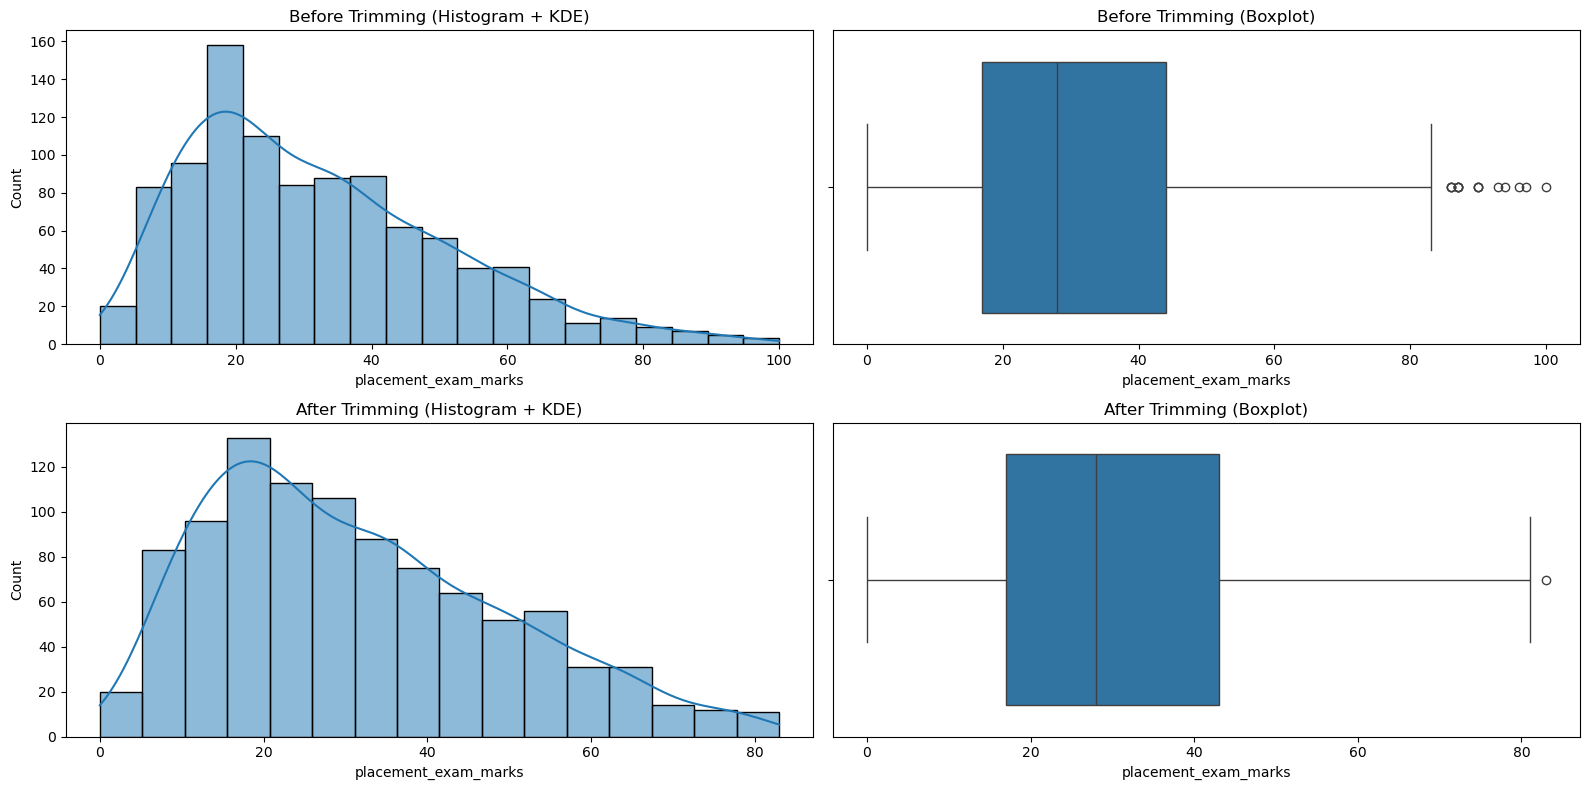

In [7]:
new_df_trim = df[(df["placement_exam_marks"] >= lower_limit) & (df["placement_exam_marks"] <= upper_limit)].copy()

print("\n✅ Shape after Trimming:", new_df_trim.shape)

# -------------------------------
# Step 6) Compare Before vs After (Trimming)
# -------------------------------
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
sns.histplot(df["placement_exam_marks"], kde=True)
plt.title("Before Trimming (Histogram + KDE)")

plt.subplot(2, 2, 2)
sns.boxplot(x=df["placement_exam_marks"])
plt.title("Before Trimming (Boxplot)")

plt.subplot(2, 2, 3)
sns.histplot(new_df_trim["placement_exam_marks"], kde=True)
plt.title("After Trimming (Histogram + KDE)")

plt.subplot(2, 2, 4)
sns.boxplot(x=new_df_trim["placement_exam_marks"])
plt.title("After Trimming (Boxplot)")

plt.tight_layout()
plt.show()

# ✅ METHOD 2: CAPPING (Winsorization)


In [9]:
# NOTE: np.where(condition, true_value, false_value)
# ============================================================
new_df_cap = df.copy()

new_df_cap["placement_exam_marks"] = np.where(
    new_df_cap["placement_exam_marks"] > upper_limit,
    upper_limit,
    np.where(
        new_df_cap["placement_exam_marks"] < lower_limit,
        lower_limit,
        new_df_cap["placement_exam_marks"]
    )
)

print("\n✅ Shape after Capping:", new_df_cap.shape)


✅ Shape after Capping: (1000, 3)


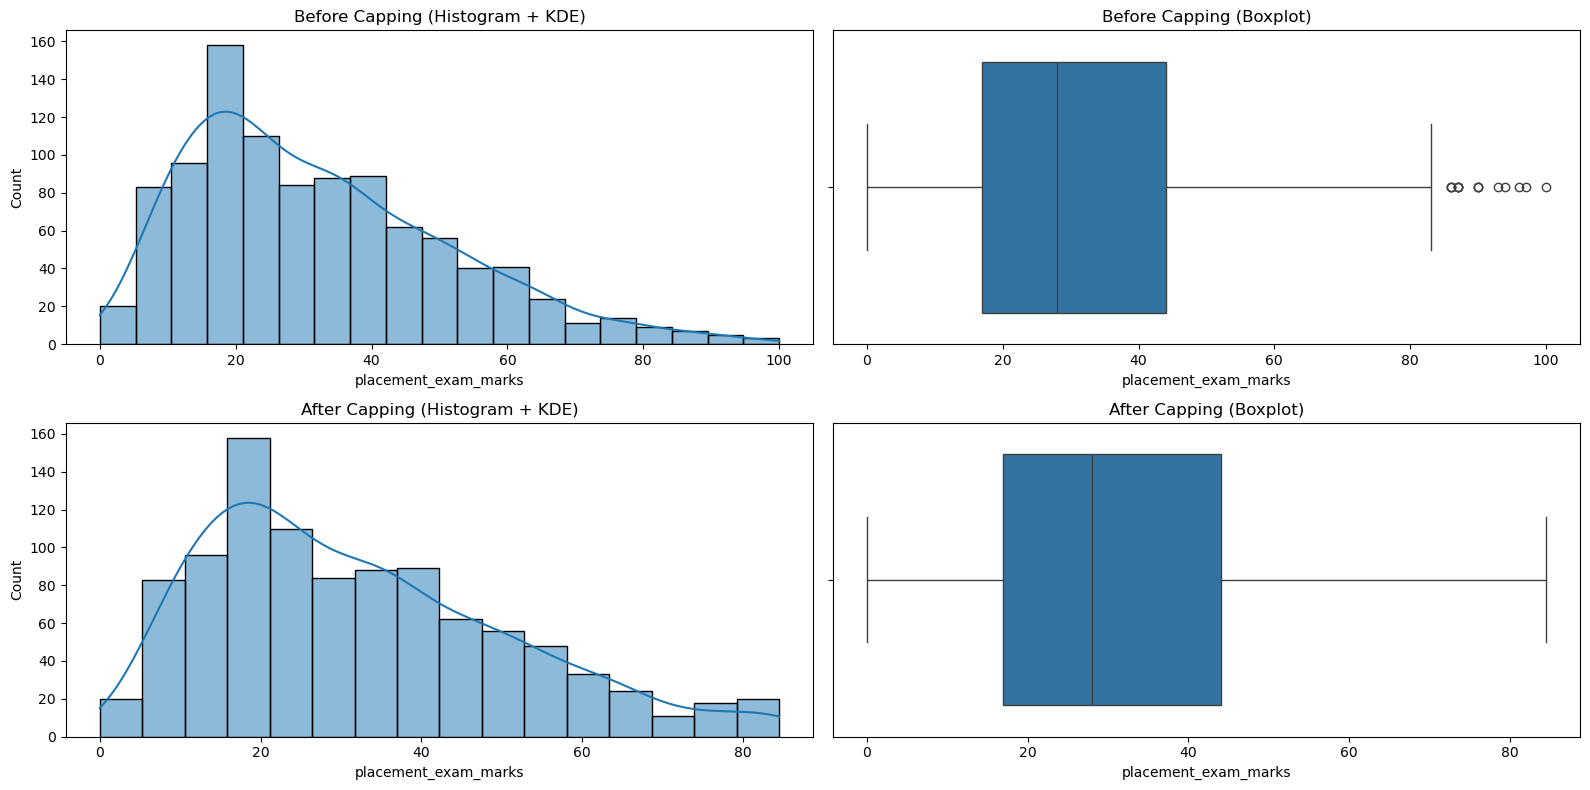

In [10]:
# Step 7) Compare Before vs After (Capping)
# -------------------------------
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
sns.histplot(df["placement_exam_marks"], kde=True)
plt.title("Before Capping (Histogram + KDE)")

plt.subplot(2, 2, 2)
sns.boxplot(x=df["placement_exam_marks"])
plt.title("Before Capping (Boxplot)")

plt.subplot(2, 2, 3)
sns.histplot(new_df_cap["placement_exam_marks"], kde=True)
plt.title("After Capping (Histogram + KDE)")

plt.subplot(2, 2, 4)
sns.boxplot(x=new_df_cap["placement_exam_marks"])
plt.title("After Capping (Boxplot)")

plt.tight_layout()
plt.show()